<a href="https://colab.research.google.com/github/kaorilivia-tech/Calculo-numerico/blob/main/Tarefa_Interpola%C3%A7%C3%A3o_Erro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Códigos fornecidos pelo enunciado**

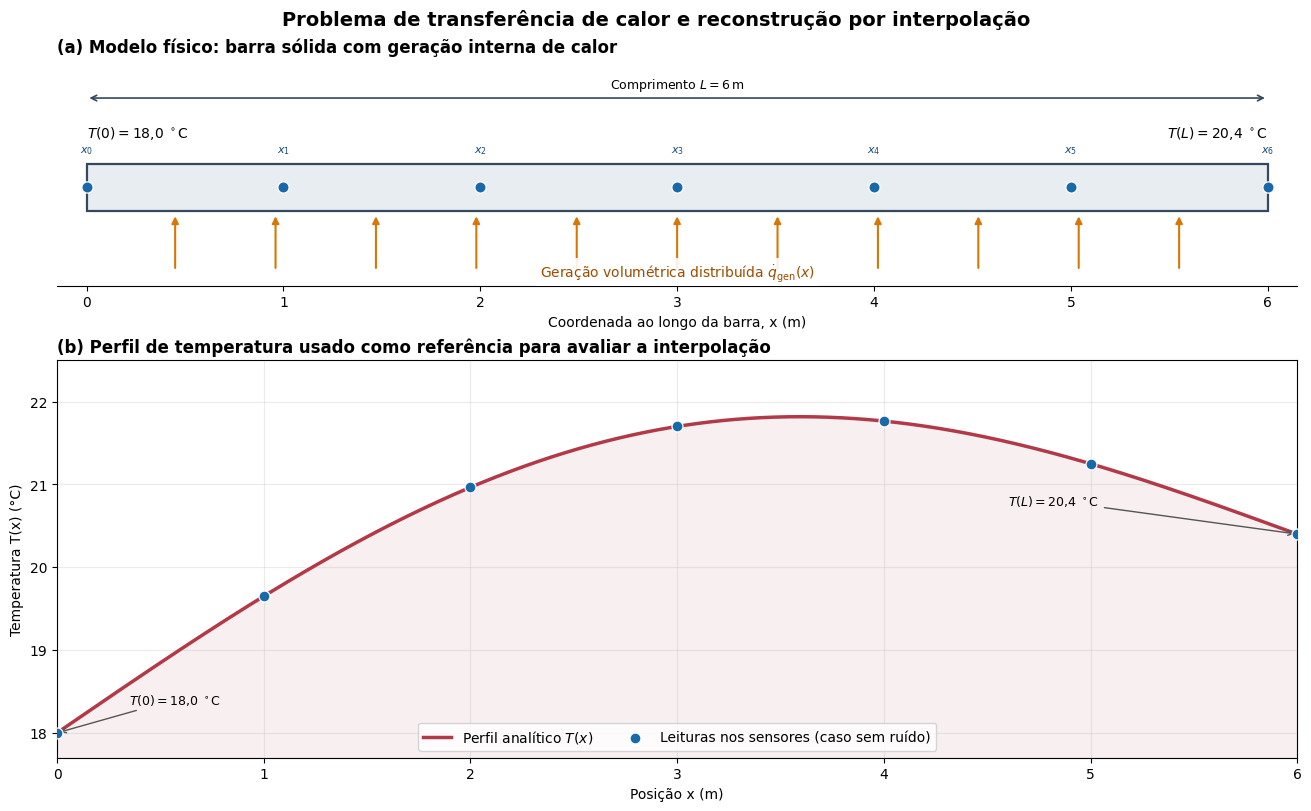

Temperaturas nas extremidades: T(0)=18.0 °C e T(L)=20.4 °C


In [9]:
# Preparação do modelo e bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import BarycentricInterpolator, interp1d, CubicSpline
from matplotlib.patches import Rectangle

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (9, 5)
L = 6.0  # comprimento da barra, m

def temperatura_real(x):
    """Perfil analítico de referência em °C; x é dado em metros."""
    x = np.asarray(x, dtype=float)
    xi = x/L
    return 18 + 2.4*xi + 2.5*np.sin(np.pi*xi)

x_min, x_max = 0.0, L
x_fino = np.linspace(x_min, x_max, 2001)
T_fino = temperatura_real(x_fino)

# Figura do problema: esquema físico e perfil analítico em painéis separados

x_sensores_fig = np.linspace(0, L, 7)
T_sensores_fig = temperatura_real(x_sensores_fig)

fig = plt.figure(figsize=(13, 8), constrained_layout=True)
gs = fig.add_gridspec(2, 1, height_ratios=[0.85, 1.5])
ax_esq = fig.add_subplot(gs[0])
ax_perfil = fig.add_subplot(gs[1])

# Painel (a): barra física, sensores e fonte interna distribuída
ax_esq.set_title("(a) Modelo físico: barra sólida com geração interna de calor", loc="left", fontsize=12, weight="bold")
barra_y, barra_h = 0.40, 0.25
ax_esq.add_patch(Rectangle((0, barra_y), L, barra_h, facecolor="#e8edf2",
                           edgecolor="#34495e", linewidth=1.6, zorder=1))
# Sensores ao longo do eixo da barra
ax_esq.scatter(x_sensores_fig, np.full_like(x_sensores_fig, barra_y+barra_h/2),
               s=65, marker="o", facecolor="#1769aa", edgecolor="white", linewidth=0.9,
               zorder=4, label="Sensores")
# Aquecimento interno: setas iguais identificam geração distribuída, sem sugerir fluxo de calor externo
for xpos in np.linspace(0.45, 5.55, 11):
    ax_esq.annotate("", xy=(xpos, barra_y-0.015), xytext=(xpos, 0.08),
                    arrowprops={"arrowstyle":"-|>", "color":"#d97706", "lw":1.5}, zorder=3)
ax_esq.text(L/2, 0.015, r"Geração volumétrica distribuída $\dot{q}_{\mathrm{gen}}(x)$",
            ha="center", va="bottom", color="#9a4d00", fontsize=10,
            bbox={"facecolor":"white", "edgecolor":"none", "alpha":0.88, "pad":2.5})
ax_esq.text(0, 0.77, r"$T(0)=18{,}0\ ^\circ\mathrm{C}$", ha="left", va="bottom", fontsize=10)
ax_esq.text(L, 0.77, r"$T(L)=20{,}4\ ^\circ\mathrm{C}$", ha="right", va="bottom", fontsize=10)
# Linha de dimensão e eixo longitudinal
ax_esq.annotate("", xy=(L, 1.00), xytext=(0, 1.00),
                arrowprops={"arrowstyle":"<->", "color":"#34495e", "lw":1.2})
ax_esq.text(L/2, 1.025, r"Comprimento $L=6\,\mathrm{m}$", ha="center", va="bottom", fontsize=9)
for i, xpos in enumerate(x_sensores_fig):
    ax_esq.text(xpos, barra_y+barra_h+0.04, rf"$x_{i}$", ha="center", va="bottom", fontsize=8, color="#174a73")
ax_esq.set_xlim(-0.15, L+0.15); ax_esq.set_ylim(0, 1.2)
ax_esq.set_xlabel("Coordenada ao longo da barra, x (m)")
ax_esq.set_yticks([]); ax_esq.grid(False)
for spine in ["left", "right", "top"]: ax_esq.spines[spine].set_visible(False)

# Painel (b): curva de referência e posições amostradas
ax_perfil.set_title("(b) Perfil de temperatura usado como referência para avaliar a interpolação",
                    loc="left", fontsize=12, weight="bold")
ax_perfil.plot(x_fino, T_fino, color="#b23a48", linewidth=2.5,
               label=r"Perfil analítico $T(x)$", zorder=2)
ax_perfil.scatter(x_sensores_fig, T_sensores_fig, s=62, marker="o",
                  facecolor="#1769aa", edgecolor="white", linewidth=0.9,
                  label="Leituras nos sensores (caso sem ruído)", zorder=4)
ax_perfil.fill_between(x_fino, T_fino, np.min(T_fino)-0.3,
                       color="#b23a48", alpha=0.08, zorder=1)
ax_perfil.annotate(r"$T(0)=18{,}0\ ^\circ\mathrm{C}$",
                   xy=(0, temperatura_real(0)), xytext=(0.35, 18.35),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.annotate(r"$T(L)=20{,}4\ ^\circ\mathrm{C}$",
                   xy=(L, temperatura_real(L)), xytext=(4.6, 20.75),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.set_xlim(0, L); ax_perfil.set_ylim(17.7, 22.5)
ax_perfil.set_xlabel("Posição x (m)")
ax_perfil.set_ylabel("Temperatura T(x) (°C)")
ax_perfil.grid(True, alpha=0.25); ax_perfil.legend(loc="lower center", ncol=2, frameon=True)
fig.suptitle("Problema de transferência de calor e reconstrução por interpolação", fontsize=14, weight="bold")
plt.show()

print(f"Temperaturas nas extremidades: T(0)={temperatura_real(0):.1f} °C e T(L)={temperatura_real(L):.1f} °C")

In [10]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    # S_i(x_i)=y_i
    for i in range(n):
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    # S_i(x_(i+1))=y_(i+1)
    for i in range(n):
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    # Continuidade da primeira derivada nos nós internos
    for i in range(n-1):
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    # Condição de contorno: c_0=0
    A[row, 2*n] = 1
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário: interpoladores callable para quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange,
            "Spline linear": linear,
            "Spline quadrática": quad,
            "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


In [11]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    # S_i(x_i)=y_i
    for i in range(n):
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    # S_i(x_(i+1))=y_(i+1)
    for i in range(n):
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    # Continuidade da primeira derivada nos nós internos
    for i in range(n-1):
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    # Condição de contorno: c_0=0
    A[row, 2*n] = 1
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário: interpoladores callable para quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange,
            "Spline linear": linear,
            "Spline quadrática": quad,
            "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


#**Etapa 1: Interpolação com dados exatos**

O Lagrabde global foi o mais preciso, com erro máximo de 8,5 x 10⁻⁵ °C. A spline cúbica natural ficou em 2,4 x 10⁻² °C e a linear em 8,2 x 10⁻² °C. O erro de Lagrange se concentra nos intervalos das extremidades.

,Método,Erro máximo (°C),MAE (°C),RMSE (°C)
0,Lagrange global,0.000085,0.000019,0.000033
1,Spline cúbica natural,0.000506,0.000184,0.000239
2,Spline quadrática,0.023927,0.014950,0.016466
3,Spline linear,0.082294,0.036510,0.043967


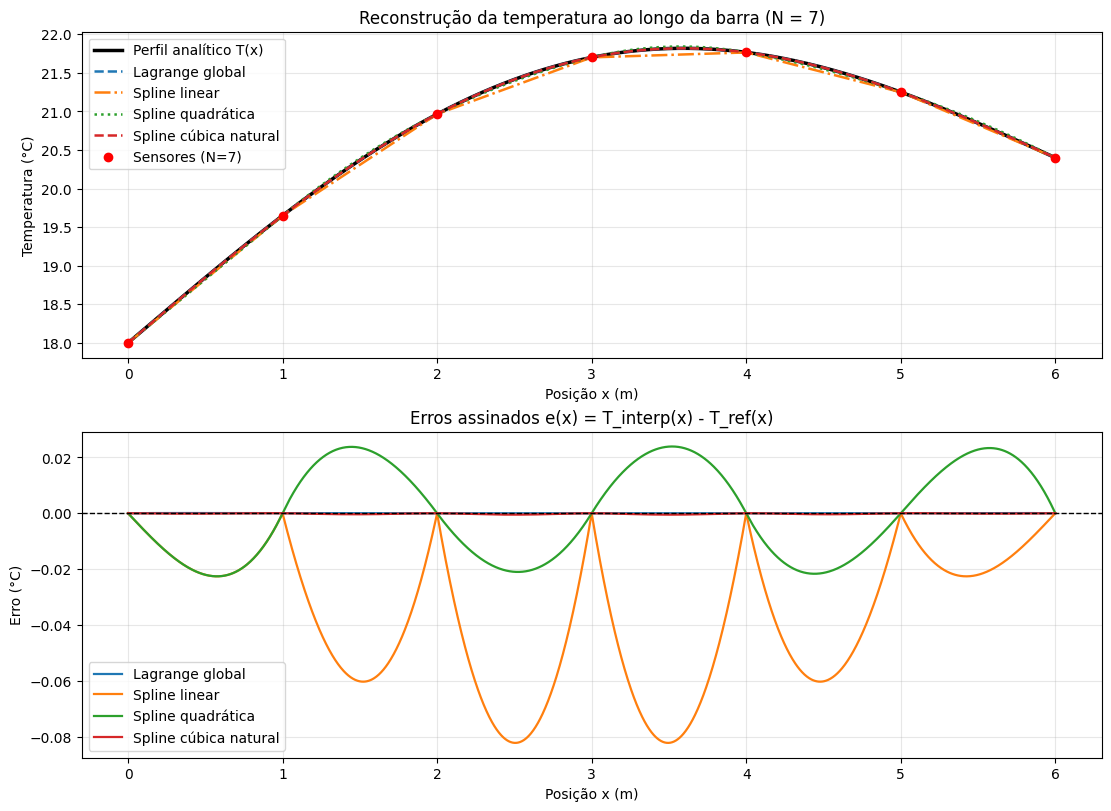

In [12]:
# 1. Criação dos 7 nós equiespaçados e dos interpoladores
x_nos_7 = np.linspace(x_min, x_max, 7)
y_nos_7 = temperatura_real(x_nos_7)
metodos_7 = criar_metodos(x_nos_7, y_nos_7)

# 2. Tabela de métricas na malha fina
metricas_7 = calcular_metricas(metodos_7, x_fino, T_fino)
display(metricas_7)

# 3. Gráficos: temperaturas reconstruídas e erros assinados
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 8), constrained_layout=True)

# Painel superior: curvas de temperatura
ax1.plot(x_fino, T_fino, "k-", lw=2.5, label="Perfil analítico T(x)")
estilos = ["--", "-.", ":", "--"]
for (nome, metodo), ls in zip(metodos_7.items(), estilos):
    ax1.plot(x_fino, metodo(x_fino), linestyle=ls, lw=1.8, label=nome)
ax1.scatter(x_nos_7, y_nos_7, color="red", zorder=5, label="Sensores (N=7)")
ax1.set_title("Reconstrução da temperatura ao longo da barra (N = 7)")
ax1.set_xlabel("Posição x (m)")
ax1.set_ylabel("Temperatura (°C)")
ax1.grid(True, alpha=0.3)
ax1.legend()

# Painel inferior: erros assinados e(x) = T_interp(x) - T_ref(x)
for nome, metodo in metodos_7.items():
    erro = np.asarray(metodo(x_fino)) - T_fino
    ax2.plot(x_fino, erro, lw=1.6, label=nome)
ax2.axhline(0, color="black", lw=1, ls="--")
ax2.set_title("Erros assinados e(x) = T_interp(x) - T_ref(x)")
ax2.set_xlabel("Posição x (m)")
ax2.set_ylabel("Erro (°C)")
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.show()

#**Etapa 2:  Número e posição dos sensores**

**Análise da redução do erro e relação com a estrutura T(x)**

Os resultados mostram que a distribuição de nós de Chebyshev-Lobatto reduz tanto o erro máximo ($E_{\max}$) quanto o $\text{RMSE}$ em aproximadamente uma ordem de grandeza em relação aos nós equiespaçados para todos os valores testados ($N = 5, 9, 13, 17$), atingindo o limite da precisão de máquina ($\approx 1{,}42 \times 10^{-14}\ ^\circ\text{C}$) em $N = 17$.   Contudo, essa convergência rápida mesmo com nós equiespaçados deve-se ao fato de o perfil analítico escolhido, $T(x) = 18 + 2{,}4\xi + 2{,}5\sin(\pi\xi)$, ser uma função inteira e infinitamente diferenciável ($C^\infty$), sem singularidades próximas ao intervalo $[0, L]$ no plano complexo e com derivadas de ordem superior limitadas ($\left\vert{}T^{(n)}(x)\right\vert{} = 2{,}5(\pi/L)^n \vert{}\sin(\pi x/L)\vert{}$, em que $\pi/L \approx 0{,}524 < 1$). Por isso, o termo de resto de Cauchy da interpolação polinomial decai rapidamente e o fenômeno de Runge clássico não se manifesta para $N \le 17$. Em perfis reais com gradientes abruptos, fontes concentradas ou polos próximos ao domínio real, os nós equiespaçados apresentariam fortes oscilações nas extremidades, tornando o uso de nós de Chebyshev ainda mais crítico

In [14]:
print("\n=== ETAPA 2: Lagrange Equiespaçado vs. Chebyshev-Lobatto ===")
def nos_chebyshev_lobatto(a, b, N):
    k = np.arange(N)
    z = np.cos(k * np.pi / (N - 1))
    return np.sort((a + b) / 2 + (b - a) * z / 2)

linhas_e2 = []
for N in [5, 9, 13, 17]:
    for dist, x_nos in [
        ("Equiespaçado", np.linspace(x_min, x_max, N)),
        ("Chebyshev-Lobatto", nos_chebyshev_lobatto(x_min, x_max, N)),
    ]:
        y_nos = temperatura_real(x_nos)
        interp_lag = BarycentricInterpolator(x_nos, y_nos)
        erro = interp_lag(x_fino) - T_fino
        linhas_e2.append({
            "N": N,
            "Distribuição": dist,
            "Erro máximo (°C)": np.max(np.abs(erro)),
            "RMSE (°C)": np.sqrt(np.mean(erro**2)),
        })

tabela_nos = pd.DataFrame(linhas_e2)
display(tabela_nos)


=== ETAPA 2: Lagrange Equiespaçado vs. Chebyshev-Lobatto ===


,N,Distribuição,Erro máximo (°C),RMSE (°C)
0,5,Equiespaçado,4.530257e-03,2.159567e-03
1,5,Chebyshev-Lobatto,2.326599e-03,1.532697e-03
2,9,Equiespaçado,1.043537e-06,3.438146e-07
3,9,Chebyshev-Lobatto,2.167582e-07,1.202332e-07
4,13,Equiespaçado,5.908873e-11,1.545487e-11
5,13,Chebyshev-Lobatto,3.623768e-12,1.931994e-12
6,17,Equiespaçado,1.989520e-12,2.445428e-13
7,17,Chebyshev-Lobatto,1.065814e-14,3.859088e-15


#**Etapa 3:VARREDURA DE N = 4 A 40, CUSTO E ESTABILIDADE**

Não existe um único método superior para todo $N$:

Para $N$ muito pequeno ($N = 4$): A spline cúbica natural é superior ($E_{\max} \approx 0{,}0102\ ^\circ\text{C}$ e $\text{RMSE} \approx 0{,}0048\ ^\circ\text{C}$), apresentando erro cerca de 10 vezes menor que o polinômio de Lagrange ($E_{\max} \approx 0{,}109\ ^\circ\text{C}$), pois a interpolação por partes representa melhor a curvatura com poucos pontos.  

 Para $N$ intermediário ($6 \le N \le 20$):

  Os métodos globais de Lagrange superam a spline cúbica com decaimento exponencial do erro, enquanto a spline cúbica converge à taxa algébrica $\mathcal{O}(h^4)$.


  Para $N$ elevado ($N > 25$):
  
  O Lagrange equiespaçado torna-se numericamente instável, pois sua constante de Lebesgue cresce exponencialmente ($\Lambda_N \sim \frac{2^N}{eN\ln N}$), amplificando erros de arredondamento de ponto flutuante nas extremidades ($E_{\max}$ volta a subir de $10^{-11}\ ^\circ\text{C}$ em $N=20$ para $8{,}01 \times 10^{-6}\ ^\circ\text{C}$ em $N=40$, ficando pior que a spline cúbica). Já o Lagrange com nós de Chebyshev-Lobatto tem crescimento logarítmico da constante de Lebesgue ($\Lambda_N \sim \mathcal{O}(\ln N)$) e permanece estável no piso da precisão de máquina ($\approx 10^{-14}\ ^\circ\text{C}$).  
  
   Custo computacional:
   
   Na construção, a spline cúbica resolve um sistema linear tridiagonal em $\mathcal{O}(N)$, enquanto a forma baricêntrica de Lagrange calcula os pesos em $\mathcal{O}(N^2)$.   Na avaliação em $M$ pontos da malha fina, a spline cúbica tem custo $\mathcal{O}(M \log N)$ (busca do subintervalo e avaliação de polinômio de grau 3), sendo assintoticamente mais rápida que Lagrange, que exige $\mathcal{O}(M \cdot N)$ operações.


=== ETAPA 3: Varredura de N = 4 a 40 ===


,N,Método,Emax (°C),RMSE (°C),Tempo Construção (s),Tempo Avaliação (s)
0,4,Lagrange Equiespaçado,1.090393e-01,6.829596e-02,0.002782,0.000567
1,4,Lagrange Chebyshev,1.429774e-01,8.094463e-02,0.000265,0.000421
2,4,Spline Cúbica Natural,1.017696e-02,4.786615e-03,0.000625,0.000158
18,10,Lagrange Equiespaçado,7.516743e-07,2.375289e-07,0.000341,0.000647
19,10,Lagrange Chebyshev,2.337620e-07,1.344155e-07,0.000280,0.000601
20,10,Spline Cúbica Natural,9.963236e-05,4.517820e-05,0.000462,0.000147
48,20,Lagrange Equiespaçado,1.210765e-11,1.185875e-12,0.000434,0.000872
49,20,Lagrange Chebyshev,1.421085e-14,4.083827e-15,0.000533,0.000855
50,20,Spline Cúbica Natural,4.899580e-06,2.211105e-06,0.000489,0.000138
78,30,Lagrange Equiespaçado,1.164628e-08,8.394596e-10,0.000704,0.001242


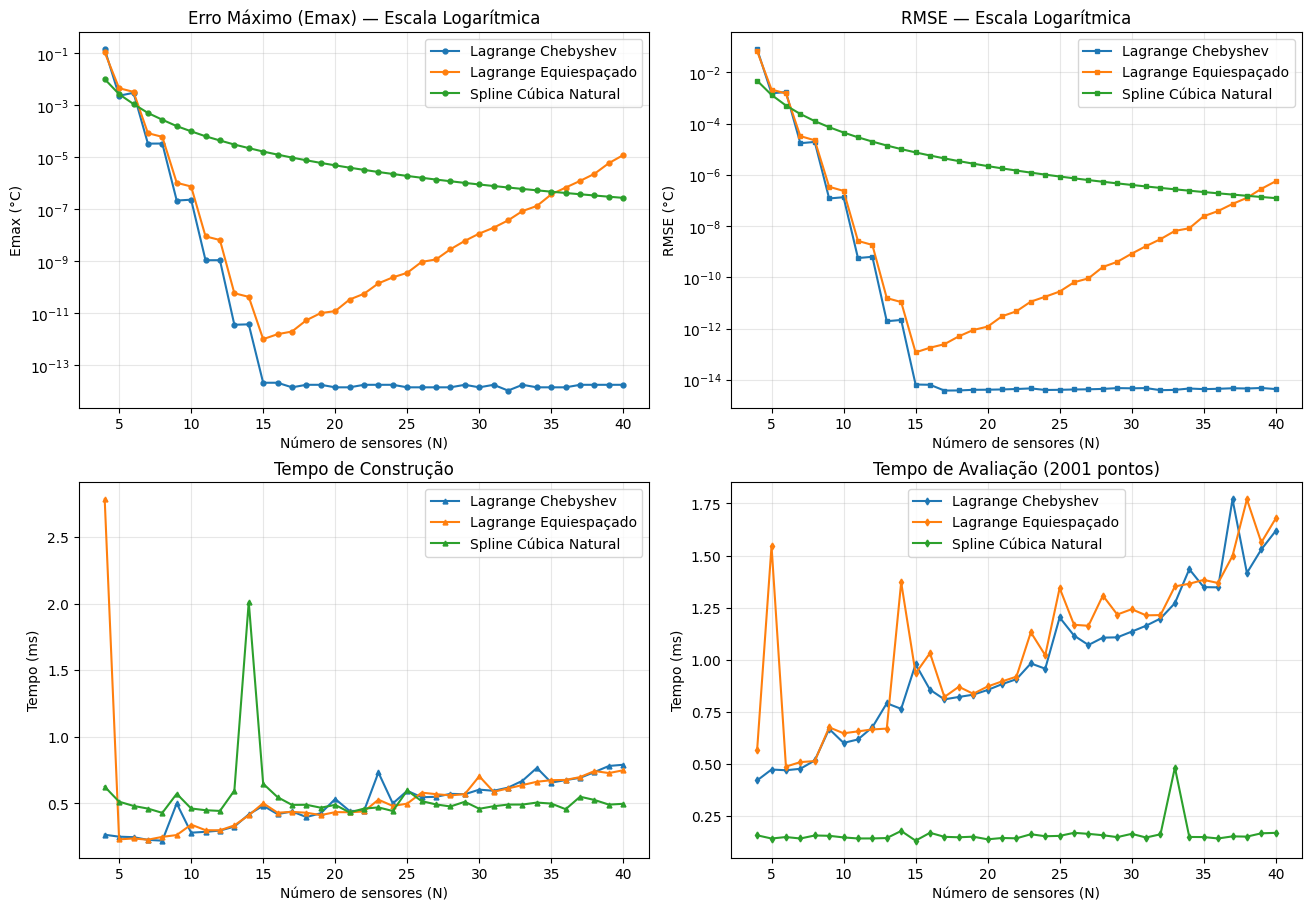

In [16]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import BarycentricInterpolator, CubicSpline

def nos_chebyshev_lobatto(a, b, N):
    k = np.arange(N)
    z = np.cos(k * np.pi / (N - 1))
    return np.sort((a + b) / 2 + (b - a) * z / 2)

print("\n=== ETAPA 3: Varredura de N = 4 a 40 ===")
Ns = np.arange(4, 41)
res_e3 = []

for N in Ns:
    x_eq = np.linspace(x_min, x_max, N)
    y_eq = temperatura_real(x_eq)
    x_ch = nos_chebyshev_lobatto(x_min, x_max, N)
    y_ch = temperatura_real(x_ch)

    for nome, fn_build in [
        ("Lagrange Equiespaçado", lambda: BarycentricInterpolator(x_eq, y_eq)),
        ("Lagrange Chebyshev", lambda: BarycentricInterpolator(x_ch, y_ch)),
        ("Spline Cúbica Natural", lambda: CubicSpline(x_eq, y_eq, bc_type="natural")),
    ]:
        t0 = time.perf_counter()
        modelo = fn_build()
        t_const = time.perf_counter() - t0

        t0 = time.perf_counter()
        y_pred = modelo(x_fino)
        t_aval = time.perf_counter() - t0

        erro = y_pred - T_fino
        res_e3.append({
            "N": N,
            "Método": nome,
            "Emax (°C)": np.max(np.abs(erro)),
            "RMSE (°C)": np.sqrt(np.mean(erro**2)),
            "Tempo Construção (s)": t_const,
            "Tempo Avaliação (s)": t_aval,
        })

df_e3 = pd.DataFrame(res_e3)
display(df_e3[df_e3["N"].isin([4, 10, 20, 30, 40])])

fig, axes = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)
for nome, grp in df_e3.groupby("Método"):
    axes[0, 0].semilogy(grp["N"], grp["Emax (°C)"], marker="o", ms=3.5, label=nome)
    axes[0, 1].semilogy(grp["N"], grp["RMSE (°C)"], marker="s", ms=3.5, label=nome)
    axes[1, 0].plot(grp["N"], grp["Tempo Construção (s)"] * 1e3, marker="^", ms=3.5, label=nome)
    axes[1, 1].plot(grp["N"], grp["Tempo Avaliação (s)"] * 1e3, marker="d", ms=3.5, label=nome)

axes[0, 0].set_title("Erro Máximo (Emax) — Escala Logarítmica")
axes[0, 0].set_ylabel("Emax (°C)")
axes[0, 1].set_title("RMSE — Escala Logarítmica")
axes[0, 1].set_ylabel("RMSE (°C)")
axes[1, 0].set_title("Tempo de Construção")
axes[1, 0].set_ylabel("Tempo (ms)")
axes[1, 1].set_title("Tempo de Avaliação (2001 pontos)")
axes[1, 1].set_ylabel("Tempo (ms)")

for ax in axes.flat:
    ax.set_xlabel("Número de sensores (N)")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()

plt.show()

#**Etapa 4: Estudo de Caso e decisão técnica**

**Recomendação Técnica — Reconstrução Térmica da Barra**

1. Escolha com poucos sensores exatos:

Com muito poucos sensores ($N \le 4$), recomenda-se a spline cúbica natural, que obteve $E_{\max} = 0{,}0102\ ^\circ\text{C}$ e $\text{RMSE} = 0{,}0048\ ^\circ\text{C}$, superando o polinômio de Lagrange em uma ordem de grandeza. Caso haja entre $5$ e $15$ sensores exatos e o regime térmico seja suave, recomenda-se o interpolador baricêntrico de Lagrange (preferencialmente em posições de Chebyshev-Lobatto, que atinge $\text{RMSE} = 1{,}20 \times 10^{-7}\ ^\circ\text{C}$ com $N = 9$).  

 2. Mudança de recomendação ao aumentar o número de sensores ($N$):

Ao aumentar $N$ ($N > 20$), deve-se abandonar o polinômio de Lagrange com sensores equiespaçados, pois o mau condicionamento numérico eleva o erro nas bordas ($E_{\max}$ sobe para $8{,}01 \times 10^{-6}\ ^\circ\text{C}$ em $N=40$). Se a geometria permitir posicionar sensores nos nós de Chebyshev-Lobatto, Lagrange mantém $\text{RMSE} \approx 4 \times 10^{-15}\ ^\circ\text{C}$. Caso os sensores precisem ser instalados de forma equiespaçada por restrições construtivas, a spline cúbica natural passa a ser a escolha mais segura, estável ($\text{RMSE} = 1{,}24 \times 10^{-7}\ ^\circ\text{C}$ em $N=40$) e computacionalmente rápida.  

 3. Procedimento quando os sensores apresentam ruído:

Na presença de ruído experimental, não se deve usar interpolação exata (nem Lagrange de grau alto, nem splines interpolantes), pois forçar a curva a passar exatamente pelos pontos ruidosos introduz oscilações espúrias entre os sensores, degradando drasticamente o $E_{\max}$ e o $\text{RMSE}$. Recomenda-se utilizar métodos de aproximação/suavização, como splines de suavização (calibradas pela variância do ruído), ajuste polinomial de baixo grau por mínimos quadrados e filtragem prévia por média temporal das leituras estacionárias de cada sensor.  

 4. Cuidados perto das extremidades ($x = 0$ e $x = L$):

Deve-se sempre instalar sensores nas duas extremidades ou impor diretamente as temperaturas prescritas de contorno ($T(0)$ e $T(L)$) como pontos de ancoragem. Além disso, recomenda-se adensar sensores próximo às bordas (como na distribuição de Chebyshev-Lobatto) para conter oscilações de fronteira e evitar condições artificiais sem embasamento físico, como $c_0 = 0$ da spline quadrática (que causou $E_{\max} = 0{,}0239\ ^\circ\text{C}$ junto à borda esquerda). Se o fluxo de calor nas extremidades for conhecido, deve-se preferir a spline cúbica clamped (derivada primeira fixada) em lugar da natural.

  5. Interpolação vs. Extrapolação e limitações em campo:

A interpolação estima a temperatura estritamente no interior do intervalo instrumentado $[x_0, x_{N-1}] = [0, L]$, onde o erro é controlado pelo espaçamento entre sensores. A extrapolação ($x < 0$ ou $x > L$) projeta o modelo para fora do domínio medido, região em que polinômios divergem rapidamente e splines perdem representatividade física, gerando erros inaceitáveis em $E_{\max}$ e $\text{RMSE}$.
Por fim, como a solução verdadeira $T(x)$ é desconhecida em campo, não é possível calcular diretamente $E_{\max}$, MAE ou RMSE reais. A incerteza deve ser estimada indiretamente por validação cruzada (leave-one-out) entre os sensores instalados, pela análise de consistência física do perfil térmico (ausência de picos não físicos e coerência com a geração interna de calor) e pela propagação da incerteza instrumental dos sensores.   